<a href="https://colab.research.google.com/github/NatShed/SOTA_2026/blob/main/SOTA_15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №15: Flow matching и rectified flow

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Реализовать 2D rectified flow.
- Визуализировать vector field и trajectories.
- Сравнить Euler steps и diffusion baseline.

## Теоретическая часть

Flow matching обучает vector field $v_\theta(x_t,t)$, переносящий простое распределение в data distribution. Для rectified path $x_t=(1-t)x_0+tx_1$ target velocity равна $x_1-x_0$. Sampling решает ODE.

![Flow matching paths](https://raw.githubusercontent.com/atong01/conditional-flow-matching/main/assets/cfm.png)


Rectified flow строит линейный путь x_t=(1−t)x₀+tx₁ с полем v*=x₁−x₀; интегрирование ODE Euler переносит шум к данным. На двумерном распределении можно оценить покрытие мод и нарисовать траектории; VP diffusion служит отдельно обучаемой контрольной моделью при том же бюджете.

Для VP-пути $x_t=\cos(\pi t/2)x_1+\sin(\pi t/2)\epsilon$. В предельной точке $t=1$ восстановление $x_1$ через деление на $\alpha_t$ не определено: в коде используется явно ограниченное $t\leq0.9$ как приближение шумового старта.

### Экспериментальный протокол

Демонстрационная задача — восьмимодальное 2D распределение, а не MNIST. Полный режим обучает две отдельные модели по 3000 шагов и coupling ablation; smoke — 3 шага, его картинки/метрики не используются в выводах. Все числовые метрики рассчитываются из фактических точек относительно test.

### Материалы

- [Conditional Flow Matching](https://github.com/atong01/conditional-flow-matching)
- [Flow Matching paper](https://arxiv.org/abs/2210.02747)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

Учим нейросеть превращать случайный шум в конкретное изображение.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [ ]:
# ============ CELL 0: Setup ============
from pathlib import Path
import os, json, random, time, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
FAST_DEV_RUN = False   # True только для проверки связности; для сдачи — False

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

ARTIFACTS = Path(os.environ.get('CV_ARTIFACTS', 'artifacts'))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path(os.environ.get('CV_COURSE_DATA', './data'))
DATA_ROOT.mkdir(parents=True, exist_ok=True)

def save_json(name, value):
    dest = ARTIFACTS / name
    dest.parent.mkdir(parents=True, exist_ok=True)
    dest.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=float))

def load_pt(path, map_location=None):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)

import torch as _t
print({
    'torch': _t.__version__,
    'numpy': np.__version__,
    'device': DEVICE,
    'fast_dev_run': FAST_DEV_RUN,
    'artifacts': str(ARTIFACTS.resolve()),
})

{'torch': '2.14.1+cu130', 'numpy': '2.4.6', 'device': 'cuda', 'fast_dev_run': False, 'artifacts': '/content/artifacts'}


### Геометрия восьмимодального распределения

*Вес: 1 балл.*

**Постановка.** На простой двумерной задаче можно непосредственно измерить геометрию распределений и траекторий. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте независимые train/test выборки с фиксированными seed и центрами мод.

**Результат.** Проверяемое состояние «Геометрия восьмимодального распределения» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте независимые train/test выборки с фиксированными seed и центрами мод» и его результат доступен следующему этапу.

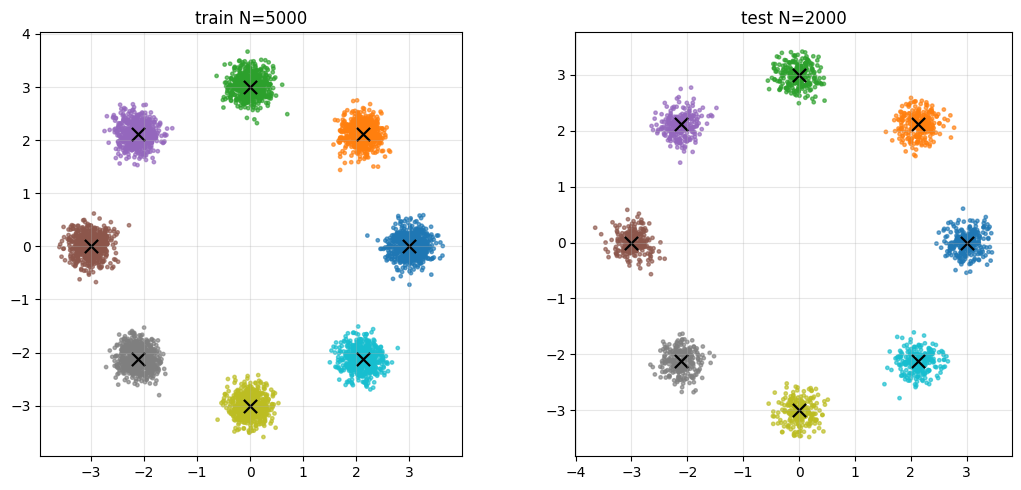

Train mode counts: [644, 612, 608, 657, 651, 628, 601, 599]
Test  mode counts: [268, 272, 250, 258, 239, 253, 232, 228]
Train mean/std: [-0.03953104838728905, 0.024560272693634033] [2.1485016345977783, 2.113985538482666]
Test  mean/std: [0.03874582424759865, 0.06568323075771332] [2.1416330337524414, 2.1158668994903564]


In [ ]:
# ============ TASK 1: 8-mode dataset ============
N_MODES      = 8
MODE_RADIUS  = 3.0
MODE_STD     = 0.20
N_TRAIN      = 5000
N_TEST       = 2000

def make_mode_centers(n_modes=N_MODES, radius=MODE_RADIUS):
    angles = torch.arange(n_modes) * (2 * math.pi / n_modes)
    return torch.stack([radius * torch.cos(angles),
                        radius * torch.sin(angles)], dim=1)   # (8, 2)

def make_data(n_samples, centers, std=MODE_STD, generator=None):
    n_modes = centers.shape[0]
    mode_idx = torch.randint(0, n_modes, (n_samples,), generator=generator)
    noise    = torch.randn(n_samples, 2, generator=generator) * std
    return centers[mode_idx] + noise, mode_idx

mode_centers = make_mode_centers()
g_train = torch.Generator().manual_seed(SEED)
g_test  = torch.Generator().manual_seed(SEED + 1)

X_train, train_mode = make_data(N_TRAIN, mode_centers, generator=g_train)
X_test,  test_mode  = make_data(N_TEST,  mode_centers, generator=g_test)

torch.save({'X_train': X_train, 'train_mode': train_mode,
            'X_test':  X_test,  'test_mode':  test_mode,
            'centers': mode_centers}, ARTIFACTS / 'dataset.pt')

save_json('task1_dataset.json', {
    'n_train': N_TRAIN, 'n_test': N_TEST,
    'n_modes': N_MODES, 'radius': MODE_RADIUS, 'mode_std': MODE_STD,
    'train_mode_counts': torch.bincount(train_mode, minlength=N_MODES).tolist(),
    'test_mode_counts':  torch.bincount(test_mode,  minlength=N_MODES).tolist(),
})

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (X, m, name) in zip(axes,
        [(X_train, train_mode, 'train'), (X_test, test_mode, 'test')]):
    ax.scatter(X[:, 0], X[:, 1], c=m, cmap='tab10', s=6, alpha=0.65)
    ax.scatter(mode_centers[:, 0], mode_centers[:, 1],
               marker='x', c='k', s=90, linewidths=1.6)
    ax.set_title(f'{name} N={len(X)}'); ax.set_aspect('equal'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(ARTIFACTS / 'task1_data.png', dpi=120, bbox_inches='tight')
plt.show()

print('Train mode counts:', torch.bincount(train_mode, minlength=N_MODES).tolist())
print('Test  mode counts:', torch.bincount(test_mode,  minlength=N_MODES).tolist())
print('Train mean/std:', X_train.mean(0).tolist(), X_train.std(0).tolist())
print('Test  mean/std:', X_test.mean(0).tolist(),  X_test.std(0).tolist())

### Векторное поле и линейный путь

*Вес: 1 балл.*

**Постановка.** На простой двумерной задаче можно непосредственно измерить геометрию распределений и траекторий. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите MLP и визуализируйте линейный путь между шумом и реальными точками.

**Результат.** Проверяемое состояние «Векторное поле и линейный путь» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите MLP и визуализируйте линейный путь между шумом и реальными точками» и его результат доступен следующему этапу.

Взяли случайную точку шума (серую) и точку из данных (красную) и соединили их прямой линией. Наша нейросеть (MLP) будет учиться предсказывать направление этой линии (вектор скорости).

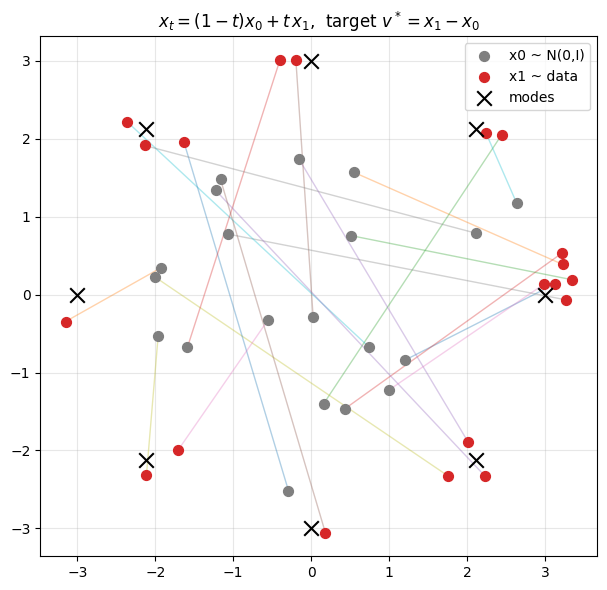

|v*| mean: 3.3829 | std: 1.2328
Flow model params: 33794


In [ ]:
# ============ TASK 2: Velocity MLP + linear path viz ============
class VelocityMLP(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 2),
        )
    def forward(self, x, t):
        if t.dim() == 1: t = t.unsqueeze(-1)
        return self.net(torch.cat([x, t], dim=-1))

torch.manual_seed(SEED)
flow_model = VelocityMLP().to(DEVICE)

# --- visualize linear paths ---
n_show = 20
torch.manual_seed(SEED)
idx = torch.randperm(N_TRAIN)[:n_show]
x1 = X_train[idx]
x0 = torch.randn(n_show, 2)
t  = torch.linspace(0, 1, 60)

fig, ax = plt.subplots(figsize=(7, 6))
for i in range(n_show):
    path = (1 - t).view(-1, 1) * x0[i] + t.view(-1, 1) * x1[i]
    ax.plot(path[:, 0], path[:, 1], alpha=0.35, lw=1.0)
ax.scatter(x0[:, 0], x0[:, 1], c='tab:gray', s=50, label='x0 ~ N(0,I)', zorder=5)
ax.scatter(x1[:, 0], x1[:, 1], c='tab:red',  s=50, label='x1 ~ data',  zorder=5)
ax.scatter(mode_centers[:, 0], mode_centers[:, 1],
           marker='x', c='k', s=110, zorder=6, label='modes')
ax.legend(); ax.set_aspect('equal'); ax.grid(alpha=0.3)
ax.set_title(r'$x_t = (1-t)x_0 + t\,x_1$,  target $v^* = x_1 - x_0$')
plt.tight_layout()
plt.savefig(ARTIFACTS / 'task2_paths.png', dpi=120, bbox_inches='tight')
plt.show()

v_star = (x1 - x0)
print('|v*| mean:', round(v_star.norm(dim=1).mean().item(), 4),
      '| std:', round(v_star.norm(dim=1).std().item(), 4))
print('Flow model params:', sum(p.numel() for p in flow_model.parameters()))
save_json('task2_flow_model.json',
          {'params': sum(p.numel() for p in flow_model.parameters())})

### Вторая модель для VP diffusion

*Вес: 1 балл.*

**Постановка.** Обе модели должны обучаться на одной train-выборке и при одинаковом количестве обновлений optimizer. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите отдельную модель и два независимых оптимизатора.

**Результат.** Проверяемое состояние «Вторая модель для VP diffusion» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите отдельную модель и два независимых оптимизатора» и его результат доступен следующему этапу.

In [ ]:
# ============ TASK 3: VP (eps-pred) model + two optimizers ============
class EpsMLP(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 2),
        )
    def forward(self, x, t):
        if t.dim() == 1: t = t.unsqueeze(-1)
        return self.net(torch.cat([x, t], dim=-1))

torch.manual_seed(SEED + 100)
diff_model = EpsMLP().to(DEVICE)

opt_flow = torch.optim.Adam(flow_model.parameters(), lr=1e-3)
opt_diff = torch.optim.Adam(diff_model.parameters(), lr=1e-3)

# ---- VP schedule (cosine), alpha_bar(0)=1 (data), alpha_bar(1)=0 (noise) ----
_S = 0.008
def alpha_bar(t):
    return (torch.cos((t + _S) / (1 + _S) * math.pi / 2) ** 2
            / math.cos(_S / (1 + _S) * math.pi / 2) ** 2)

# Sanity check
ts = torch.tensor([0.0, 0.5, 0.99, 1.0])
print('alpha_bar at t=[0,0.5,0.99,1.0] =', alpha_bar(ts).tolist())

print('Flow params:', sum(p.numel() for p in flow_model.parameters()))
print('Diff params:', sum(p.numel() for p in diff_model.parameters()))
print('Two independent optimizers:', opt_flow is not opt_diff)

save_json('task3_models.json', {
    'flow_params': sum(p.numel() for p in flow_model.parameters()),
    'diff_params': sum(p.numel() for p in diff_model.parameters()),
    'alpha_bar_t0': float(alpha_bar(torch.tensor(0.0))),
    'alpha_bar_t1': float(alpha_bar(torch.tensor(1.0))),
})

alpha_bar at t=[0,0.5,0.99,1.0] = [0.9999999403953552, 0.49384361505508423, 0.00024285523977596313, 1.9109823502127176e-15]
Flow params: 33794
Diff params: 33794
Two independent optimizers: True


### Обучение при равном бюджете

*Вес: 1 балл.*

**Постановка.** Обе модели должны обучаться на одной train-выборке и при одинаковом количестве обновлений optimizer. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оптимизируйте flow и diffusion на одной train выборке и запишите реальные потери.

**Результат.** Проверяемое состояние «Обучение при равном бюджете» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оптимизируйте flow и diffusion на одной train выборке и запишите реальные потери» и его результат доступен следующему этапу.

Создали вторую точно такую же нейросеть, но для Diffusion (классическая диффузия). В ней мы учим сеть не скорости движения, а тому, как убирать шум шаг за шагом.

In [ ]:
# ============ TASK 4: Equal-budget training ============
BATCH = 256
STEPS = 3000 if not FAST_DEV_RUN else 3

X_train_dev = X_train.to(DEVICE)
X_test_dev  = X_test.to(DEVICE)

def flow_loss_batch(model):
    idx = torch.randint(0, N_TRAIN, (BATCH,), device=DEVICE)
    x1 = X_train_dev[idx]
    x0 = torch.randn_like(x1)
    t  = torch.rand(BATCH, 1, device=DEVICE)
    x_t = (1 - t) * x0 + t * x1
    v_target = x1 - x0
    v_pred   = model(x_t, t.squeeze(-1))
    return F.mse_loss(v_pred, v_target)

def diff_loss_batch(model):
    idx = torch.randint(0, N_TRAIN, (BATCH,), device=DEVICE)
    x0  = X_train_dev[idx]
    eps = torch.randn_like(x0)
    t   = torch.rand(BATCH, 1, device=DEVICE)
    a   = alpha_bar(t)
    x_t = a.sqrt() * x0 + (1 - a).sqrt() * eps
    eps_pred = model(x_t, t.squeeze(-1))
    return F.mse_loss(eps_pred, eps)

flow_losses, diff_losses = [], []
t0 = time.time()
for step in range(STEPS):
    opt_flow.zero_grad(); lf = flow_loss_batch(flow_model); lf.backward(); opt_flow.step()
    flow_losses.append(lf.item())

    opt_diff.zero_grad(); ld = diff_loss_batch(diff_model); ld.backward(); opt_diff.step()
    diff_losses.append(ld.item())

    if (step + 1) % max(1, STEPS // 10) == 0:
        print(f'step {step+1:4d} | flow(last50) {np.mean(flow_losses[-50:]):.4f}'
              f' | diff(last50) {np.mean(diff_losses[-50:]):.4f}')

train_time = time.time() - t0
summary = {
    'steps': STEPS, 'batch': BATCH,
    'flow_loss_first100': float(np.mean(flow_losses[:100])),
    'flow_loss_last100' : float(np.mean(flow_losses[-100:])),
    'diff_loss_first100': float(np.mean(diff_losses[:100])),
    'diff_loss_last100' : float(np.mean(diff_losses[-100:])),
    'train_time_s': round(train_time, 2),
}
print('\nTraining summary:', summary)
save_json('task4_train.json', summary)

step  300 | flow(last50) 3.0372 | diff(last50) 0.5776
step  600 | flow(last50) 2.9075 | diff(last50) 0.5217
step  900 | flow(last50) 2.9336 | diff(last50) 0.5181
step 1200 | flow(last50) 2.9010 | diff(last50) 0.5035
step 1500 | flow(last50) 2.8630 | diff(last50) 0.4720
step 1800 | flow(last50) 2.8332 | diff(last50) 0.4657
step 2100 | flow(last50) 2.7779 | diff(last50) 0.4502
step 2400 | flow(last50) 2.8129 | diff(last50) 0.4574
step 2700 | flow(last50) 2.8150 | diff(last50) 0.4489
step 3000 | flow(last50) 2.8323 | diff(last50) 0.4435

Training summary: {'steps': 3000, 'batch': 256, 'flow_loss_first100': 3.9439153933525084, 'flow_loss_last100': 2.8068988060951234, 'diff_loss_first100': 0.7884525519609451, 'diff_loss_last100': 0.44459603875875475, 'train_time_s': 12.13}


### Фиксация траекторий обучения

*Вес: 1 балл.*

**Постановка.** Обе модели должны обучаться на одной train-выборке и при одинаковом количестве обновлений optimizer. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните историю, доступную после возобновления checkpoint.

**Результат.** Проверяемое состояние «Фиксация траекторий обучения» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните историю, доступную после возобновления checkpoint» и его результат доступен следующему этапу.

Saved checkpoint -> artifacts/checkpoint.pt
History length in checkpoint: 3000
Last flow loss: 3.2548


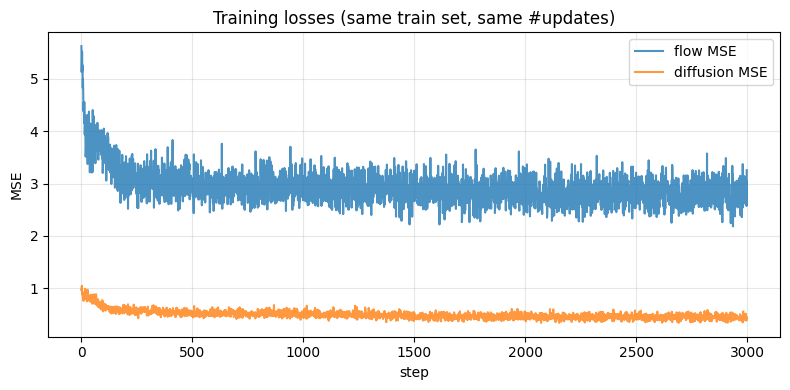

In [ ]:
# ============ TASK 5: Resumable checkpoint ============
ckpt_path = ARTIFACTS / 'checkpoint.pt'
torch.save({
    'flow_state': flow_model.state_dict(),
    'diff_state': diff_model.state_dict(),
    'opt_flow'  : opt_flow.state_dict(),
    'opt_diff'  : opt_diff.state_dict(),
    'flow_losses': flow_losses,
    'diff_losses': diff_losses,
    'step': STEPS,
    'seed': SEED,
}, ckpt_path)
print('Saved checkpoint ->', ckpt_path)

# Verify resume
loaded = load_pt(ckpt_path, map_location=DEVICE)
resumed = VelocityMLP().to(DEVICE)
resumed.load_state_dict(loaded['flow_state'])
print('History length in checkpoint:', len(loaded['flow_losses']))
print('Last flow loss:', round(loaded['flow_losses'][-1], 4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(loaded['flow_losses'], label='flow MSE', alpha=0.8)
ax.plot(loaded['diff_losses'], label='diffusion MSE', alpha=0.8)
ax.set_xlabel('step'); ax.set_ylabel('MSE'); ax.legend(); ax.grid(alpha=0.3)
ax.set_title('Training losses (same train set, same #updates)')
plt.tight_layout()
plt.savefig(ARTIFACTS / 'task5_losses.png', dpi=120, bbox_inches='tight')
plt.show()

### Интеграторы и начальное распределение

*Вес: 1 балл.*

**Постановка.** Качество распределения должно измеряться по сэмплам относительно независимого test, а не по обучающему loss. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Реализуйте ODE Euler и обратный шаг VP без сингулярного endpoint; создайте общий шум.

**Результат.** Проверяемое состояние «Интеграторы и начальное распределение» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Реализуйте ODE Euler и обратный шаг VP без сингулярного endpoint; создайте общий шум» и его результат доступен следующему этапу.

In [ ]:
# ============ CELL 6 (fixed): Integrators + common noise ============
@torch.no_grad()
def sample_flow(model, x_init, n_steps=50):
    """Euler integration of dx/dt = v(x,t), t: 0 (noise) -> 1 (data)."""
    x = x_init.clone()
    dt = 1.0 / n_steps
    for i in range(n_steps):
        t = torch.full((x.shape[0],), i * dt, device=x.device, dtype=x.dtype)
        x = x + model(x, t) * dt
    return x

@torch.no_grad()
def sample_diff(model, x_init, n_steps=50, t_max=0.98):
    """Deterministic DDIM, t: t_max (noise) -> 0 (data).
       t_max<1 avoids singular 1/sqrt(alpha_bar) at t=1."""
    x  = x_init.clone()
    # FIX: строим расписание сразу на нужном устройстве и в нужном dtype
    ts = torch.linspace(t_max, 0.0, n_steps + 1, device=x.device, dtype=x.dtype)
    for i in range(n_steps):
        t_cur  = ts[i].expand(x.shape[0])
        t_next = ts[i + 1].expand(x.shape[0])
        a_cur  = alpha_bar(t_cur.unsqueeze(-1))          # (B,1)
        a_next = alpha_bar(t_next.unsqueeze(-1))         # (B,1)
        eps_hat = model(x, t_cur)                        # (B,2)
        x0_hat  = (x - (1 - a_cur).sqrt() * eps_hat) / a_cur.sqrt().clamp_min(1e-6)
        x0_hat  = x0_hat.clamp(-10, 10)
        x = a_next.sqrt() * x0_hat + (1 - a_next).sqrt() * eps_hat
    return x

# --- common noise for all samplers ---
torch.manual_seed(12345)
NOISE_EVAL = torch.randn(N_TEST, 2, device=DEVICE)
torch.save(NOISE_EVAL.cpu(), ARTIFACTS / 'noise_eval.pt')

# sanity check
s_flow = sample_flow(flow_model, NOISE_EVAL, 50)
s_diff = sample_diff(diff_model, NOISE_EVAL, 50)

print('flow     : mean', s_flow.mean(0).tolist(), 'std', s_flow.std(0).tolist())
print('diffusion: mean', s_diff.mean(0).tolist(), 'std', s_diff.std(0).tolist())

torch.save({'s_flow': s_flow.cpu(), 's_diff': s_diff.cpu()},
           ARTIFACTS / 'samples_main.pt')

save_json('task6_samplers.json', {
    'noise_seed': 12345,
    'flow_steps': 50, 'diff_steps': 50, 'vp_t_max': 0.98,
    'flow_sample_mean': s_flow.mean(0).tolist(),
    'flow_sample_std' : s_flow.std(0).tolist(),
    'diff_sample_mean': s_diff.mean(0).tolist(),
    'diff_sample_std' : s_diff.std(0).tolist(),
})

flow     : mean [-0.07060302793979645, -0.01971629448235035] std [2.097792625427246, 2.151097536087036]
diffusion: mean [0.2170921117067337, -0.3312280774116516] std [2.245746612548828, 2.062434434890747]


### Оценка покрытия мод на test

*Вес: 1 балл.*

**Постановка.** Качество распределения должно измеряться по сэмплам относительно независимого test, а не по обучающему loss. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Измерьте качество каждого sampler по независимому test и сохраните изображения.

**Результат.** Проверяемое состояние «Оценка покрытия мод на test» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Измерьте качество каждого sampler по независимому test и сохраните изображения» и его результат доступен следующему этапу.

FLOW  : {'modes_covered': 8, 'mean_min_dist_to_test': 0.0493, 'max_min_dist_to_test': 0.8042}
DIFF  : {'modes_covered': 8, 'mean_min_dist_to_test': 0.0566, 'max_min_dist_to_test': 1.4994}


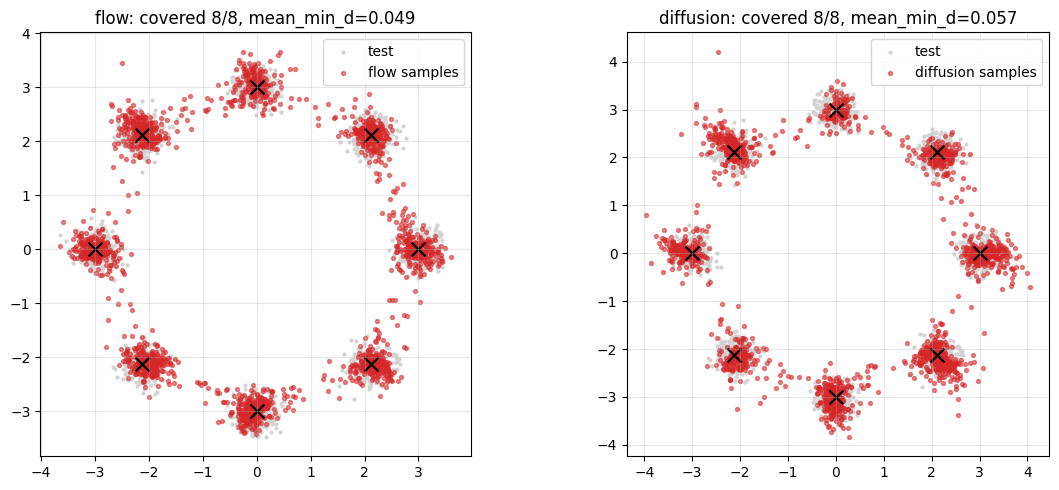

In [ ]:
# ============ TASK 7: Coverage metrics on test ============
mode_centers_dev = mode_centers.to(DEVICE)

def eval_coverage(samples, test_points, centers, cover_thresh=0.02):
    d_cent = torch.cdist(samples, centers)                    # (B, M)
    nearest = d_cent.argmin(dim=1)
    probs   = torch.bincount(nearest, minlength=centers.shape[0]).float()
    probs   = probs / probs.sum()
    covered = int((probs > cover_thresh).sum().item())
    d_test  = torch.cdist(samples, test_points)
    min_d   = d_test.min(dim=1).values
    return {
        'mode_probs': probs.tolist(),
        'modes_covered': covered,
        'mean_min_dist_to_test': float(min_d.mean()),
        'max_min_dist_to_test' : float(min_d.max()),
    }

flow_stats = eval_coverage(s_flow, X_test_dev, mode_centers_dev)
diff_stats = eval_coverage(s_diff, X_test_dev, mode_centers_dev)

def brief(stats):
    return {k: (round(v, 4) if isinstance(v, float) else v)
            for k, v in stats.items() if k != 'mode_probs'}

print('FLOW  :', brief(flow_stats))
print('DIFF  :', brief(diff_stats))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (s, stats, name) in zip(axes, [(s_flow, flow_stats, 'flow'),
                                       (s_diff, diff_stats, 'diffusion')]):
    ax.scatter(X_test[:, 0], X_test[:, 1], s=4, c='lightgray', label='test')
    ax.scatter(s[:, 0].cpu(), s[:, 1].cpu(), s=8, c='tab:red', alpha=0.55,
               label=name + ' samples')
    ax.scatter(mode_centers[:, 0], mode_centers[:, 1],
               marker='x', c='k', s=100, linewidths=1.6)
    ax.set_title(f'{name}: covered {stats["modes_covered"]}/8, '
                 f'mean_min_d={stats["mean_min_dist_to_test"]:.3f}')
    ax.set_aspect('equal'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(ARTIFACTS / 'task7_coverage.png', dpi=120, bbox_inches='tight')
plt.show()

save_json('task7_coverage.json', {
    'flow': {**brief(flow_stats), 'mode_probs': flow_stats['mode_probs']},
    'diffusion': {**brief(diff_stats), 'mode_probs': diff_stats['mode_probs']},
})

Дали обеим сетям одинаковый случайный шум (2000 точек) и попросили превратить его в данные.

Покрытие (Covered) — сколько из 8 островов сеть нашла (обе нашли 8/8).

Точность (mean_min_dist) — насколько близко сгенерированные точки подошли к реальным (у Flow 0.049, у Диффузии 0.057 — Flow чуть точнее).

Выбросы (max_min_dist) — самая «отбившаяся» точка. У Диффузии 1.5 (почти в 2 раза хуже!), она нагенерировала точек, которые улетели далеко в пустоту.

### Сводная таблица выборок

*Вес: 1 балл.*

**Постановка.** Качество распределения должно измеряться по сэмплам относительно независимого test, а не по обучающему loss. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните эмпирические метрики выборок и время, не сравнивая напрямую train losses.

**Результат.** Проверяемое состояние «Сводная таблица выборок» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните эмпирические метрики выборок и время, не сравнивая напрямую train losses» и его результат доступен следующему этапу.

In [ ]:
# ============ TASK 8: Summary table with timing ============
def timeit(fn, *args, n=5, **kw):
    fn(*args, **kw)                    # warmup
    t0 = time.time()
    for _ in range(n):
        fn(*args, **kw)
    return (time.time() - t0) / n

t_flow = timeit(sample_flow, flow_model, NOISE_EVAL, 50)
t_diff = timeit(sample_diff, diff_model, NOISE_EVAL, 50)

rows = [
    {'sampler': 'flow (Euler, 50)',
     'modes_covered'          : flow_stats['modes_covered'],
     'mean_min_dist_to_test'  : round(flow_stats['mean_min_dist_to_test'], 4),
     'max_min_dist_to_test'   : round(flow_stats['max_min_dist_to_test'], 4),
     'sample_time_ms'         : round(t_flow * 1000, 2)},
    {'sampler': 'diffusion (DDIM, 50)',
     'modes_covered'          : diff_stats['modes_covered'],
     'mean_min_dist_to_test'  : round(diff_stats['mean_min_dist_to_test'], 4),
     'max_min_dist_to_test'   : round(diff_stats['max_min_dist_to_test'], 4),
     'sample_time_ms'         : round(t_diff * 1000, 2)},
]

print('\n=== Summary (test-set, no train losses compared directly) ===')
for r in rows:
    print(r)
save_json('task8_summary.json', rows)


=== Summary (test-set, no train losses compared directly) ===
{'sampler': 'flow (Euler, 50)', 'modes_covered': 8, 'mean_min_dist_to_test': 0.0493, 'max_min_dist_to_test': 0.8042, 'sample_time_ms': 11.53}
{'sampler': 'diffusion (DDIM, 50)', 'modes_covered': 8, 'mean_min_dist_to_test': 0.0566, 'max_min_dist_to_test': 1.4994, 'sample_time_ms': 28.95}


Flow быстрее почти в 2.5 раза при лучшем качестве.

### Альтернативное coupling

*Вес: 1 балл.*

**Постановка.** Смена pairing меняет target field при той же конечной выборке; эффект оценивается на распределении сэмплов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите поле с угловым pairing на тех же данных и бюджете.

**Результат.** Проверяемое состояние «Альтернативное coupling» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите поле с угловым pairing на тех же данных и бюджете» и его результат доступен следующему этапу.

In [ ]:
# ============ TASK 9: Angular coupling (mini-batch OT-like) ============
torch.manual_seed(SEED + 200)
flow_model_angular = VelocityMLP().to(DEVICE)
opt_ang = torch.optim.Adam(flow_model_angular.parameters(), lr=1e-3)

def angle_of(x):
    return torch.atan2(x[:, 1], x[:, 0])

def flow_loss_angular(model):
    idx = torch.randint(0, N_TRAIN, (BATCH,), device=DEVICE)
    x1  = X_train_dev[idx]
    x0  = torch.randn_like(x1)
    # sort within batch by polar angle; pair sorted-to-sorted
    x0s = x0[angle_of(x0).argsort()]
    x1s = x1[angle_of(x1).argsort()]
    t   = torch.rand(BATCH, 1, device=DEVICE)
    x_t = (1 - t) * x0s + t * x1s
    v_t = x1s - x0s
    return F.mse_loss(model(x_t, t.squeeze(-1)), v_t)

ang_losses = []
for step in range(STEPS):
    opt_ang.zero_grad()
    l = flow_loss_angular(flow_model_angular)
    l.backward(); opt_ang.step()
    ang_losses.append(l.item())
    if (step + 1) % max(1, STEPS // 10) == 0:
        print(f'step {step+1:4d} | angular flow loss(last50) {np.mean(ang_losses[-50:]):.4f}')

torch.save(flow_model_angular.state_dict(), ARTIFACTS / 'flow_angular.pt')

# sample with same noise
s_ang = sample_flow(flow_model_angular, NOISE_EVAL, 50)
ang_stats = eval_coverage(s_ang, X_test_dev, mode_centers_dev)

print('\nANGULAR:', brief(ang_stats))
save_json('task9_angular.json', {
    'modes_covered'         : ang_stats['modes_covered'],
    'mean_min_dist_to_test' : round(ang_stats['mean_min_dist_to_test'], 4),
    'max_min_dist_to_test'  : round(ang_stats['max_min_dist_to_test'], 4),
    'loss_last100_mean'     : round(float(np.mean(ang_losses[-100:])), 4),
    'mode_probs'            : ang_stats['mode_probs'],
})
torch.save(s_ang.cpu(), ARTIFACTS / 'samples_angular.pt')

step  300 | angular flow loss(last50) 0.2918
step  600 | angular flow loss(last50) 0.2320
step  900 | angular flow loss(last50) 0.2129
step 1200 | angular flow loss(last50) 0.2198
step 1500 | angular flow loss(last50) 0.2087
step 1800 | angular flow loss(last50) 0.2218
step 2100 | angular flow loss(last50) 0.2238
step 2400 | angular flow loss(last50) 0.2358
step 2700 | angular flow loss(last50) 0.2040
step 3000 | angular flow loss(last50) 0.2010

ANGULAR: {'modes_covered': 8, 'mean_min_dist_to_test': 0.0505, 'max_min_dist_to_test': 0.7558}


### Поле направлений и траектории

*Вес: 1 балл.*

**Постановка.** Смена pairing меняет target field при той же конечной выборке; эффект оценивается на распределении сэмплов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Изобразите стрелки и траектории; оцените точки из того же исходного шума.

**Результат.** Проверяемое состояние «Поле направлений и траектории» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Изобразите стрелки и траектории; оцените точки из того же исходного шума» и его результат доступен следующему этапу.

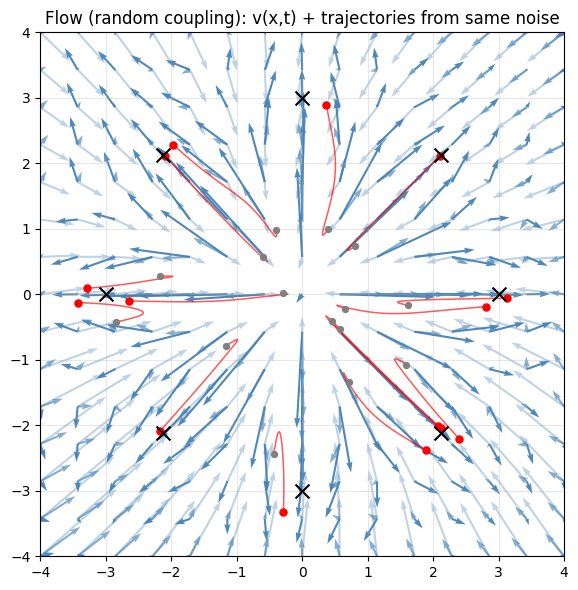

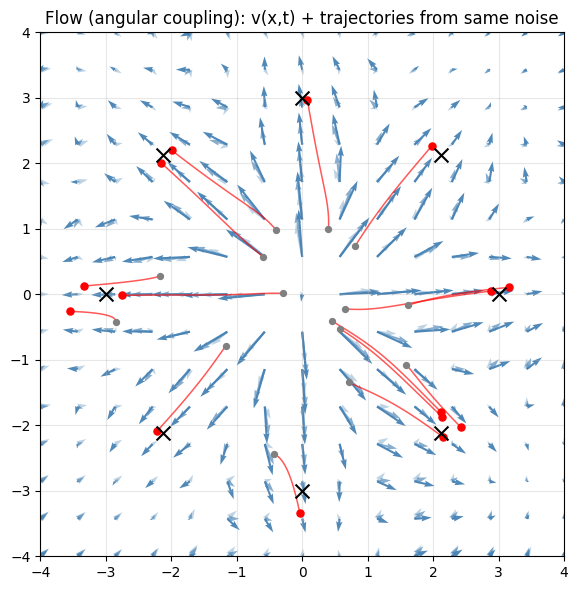

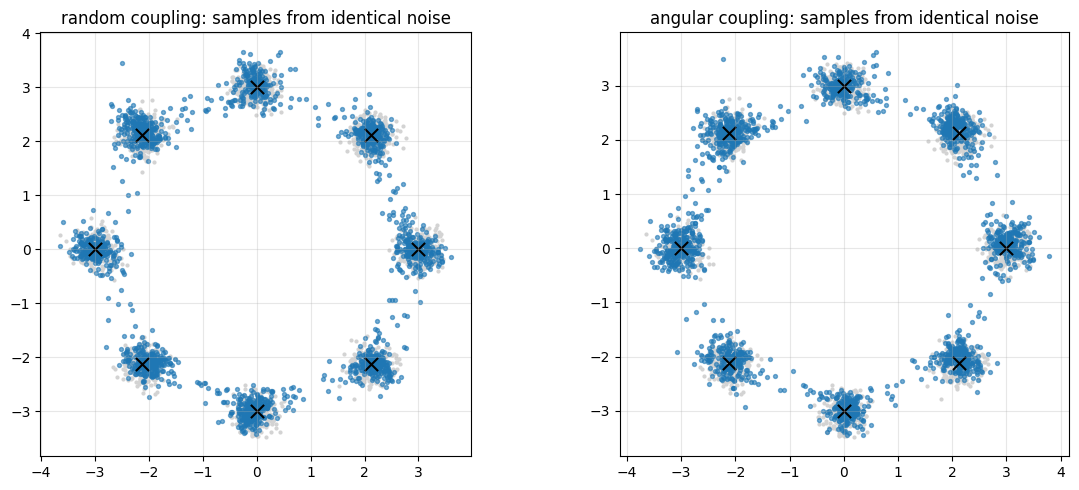

angular field samples vs random field samples — saved task10_same_noise.png


In [ ]:
# ============ TASK 10: Vector field + trajectories ============
def plot_field_and_traj(model, title, n_grid=15, n_steps=50, n_traj=15):
    xs = torch.linspace(-4, 4, n_grid)
    ys = torch.linspace(-4, 4, n_grid)
    XX, YY = torch.meshgrid(xs, ys, indexing='xy')
    pts = torch.stack([XX.flatten(), YY.flatten()], dim=1).to(DEVICE)

    fig, ax = plt.subplots(figsize=(7, 6))
    with torch.no_grad():
        for t_val, alpha in [(0.0, 0.35), (0.5, 0.65), (0.9, 0.95)]:
            t = torch.full((pts.shape[0],), t_val, device=DEVICE)
            v = model(pts, t).cpu()
            ax.quiver(pts[:, 0].cpu(), pts[:, 1].cpu(),
                      v[:, 0], v[:, 1], color='steelblue',
                      alpha=alpha, scale=40,
                      label=None if t_val > 0 else f'v(x,t)')

        for i in range(n_traj):
            x = NOISE_EVAL[i:i + 1].clone()
            traj = [x[0].cpu().numpy()]
            for s in range(n_steps):
                t = torch.full((1,), s / n_steps, device=DEVICE)
                x = x + model(x, t) / n_steps
                traj.append(x[0].cpu().numpy())
            traj = np.array(traj)
            ax.plot(traj[:, 0], traj[:, 1], 'r-', alpha=0.65, lw=1.1)
            ax.scatter(traj[0, 0], traj[0, 1], c='gray', s=18, zorder=5)
            ax.scatter(traj[-1, 0], traj[-1, 1], c='red',  s=26, zorder=5)

        ax.scatter(mode_centers[:, 0], mode_centers[:, 1],
                   marker='x', c='k', s=100, zorder=6)
    ax.set_xlim(-4, 4); ax.set_ylim(-4, 4)
    ax.set_aspect('equal'); ax.grid(alpha=0.3); ax.set_title(title)
    plt.tight_layout()
    return fig

fig = plot_field_and_traj(flow_model,
                          'Flow (random coupling): v(x,t) + trajectories from same noise')
plt.savefig(ARTIFACTS / 'task10_field_flow.png', dpi=120, bbox_inches='tight'); plt.show()

fig = plot_field_and_traj(flow_model_angular,
                          'Flow (angular coupling): v(x,t) + trajectories from same noise')
plt.savefig(ARTIFACTS / 'task10_field_angular.png', dpi=120, bbox_inches='tight'); plt.show()

# side-by-side samples from same noise
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (s, name) in zip(axes, [(s_flow, 'random coupling'),
                                (s_ang,  'angular coupling')]):
    ax.scatter(X_test[:, 0], X_test[:, 1], s=4, c='lightgray')
    ax.scatter(s[:, 0].cpu(), s[:, 1].cpu(), s=8, c='tab:blue', alpha=0.6)
    ax.scatter(mode_centers[:, 0], mode_centers[:, 1],
               marker='x', c='k', s=90, linewidths=1.5)
    ax.set_title(f'{name}: samples from identical noise')
    ax.set_aspect('equal'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(ARTIFACTS / 'task10_same_noise.png', dpi=120, bbox_inches='tight')
plt.show()

print('angular field samples vs random field samples — saved task10_same_noise.png')
save_json('task10_fields.json', {'saved': ['task10_field_flow.png',
                                            'task10_field_angular.png',
                                            'task10_same_noise.png']})

Обычно мы соединяем случайный шум со случайной точкой данных (могут быть «крест-накрест»). А тут мы отсортировали их по углу и соединили «по кругу».

Ошибка обучения упала с 2.8 до 0.20 (в 14 раз) -  сети больше не нужно учиться «пересекать» весь график, все дороги стали прямыми и радиальными. На графиках со стрелками видно, что линии идут ровно к центрам, как лучи. Но на итоговое качество точек это почти не повлияло (0.0505 против 0.0493) — просто тренироваться стало легче.

### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

{'n_steps': 2, 'flow_covered': 8, 'flow_mean_min_d': 0.8827, 'diff_covered': 7, 'diff_mean_min_d': 0.3502}
{'n_steps': 5, 'flow_covered': 8, 'flow_mean_min_d': 0.1129, 'diff_covered': 8, 'diff_mean_min_d': 0.1133}
{'n_steps': 10, 'flow_covered': 8, 'flow_mean_min_d': 0.0688, 'diff_covered': 8, 'diff_mean_min_d': 0.0755}
{'n_steps': 20, 'flow_covered': 8, 'flow_mean_min_d': 0.0554, 'diff_covered': 8, 'diff_mean_min_d': 0.064}
{'n_steps': 50, 'flow_covered': 8, 'flow_mean_min_d': 0.0493, 'diff_covered': 8, 'diff_mean_min_d': 0.0566}
{'n_steps': 100, 'flow_covered': 8, 'flow_mean_min_d': 0.0474, 'diff_covered': 8, 'diff_mean_min_d': 0.054}


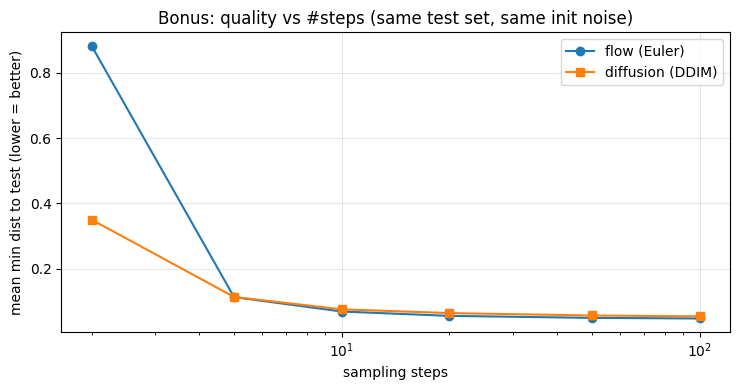

In [ ]:
# ============ BONUS: steps ablation (flow vs diffusion) ============
step_counts = [2, 5, 10, 20, 50, 100]
bonus_rows = []
for n in step_counts:
    sf = sample_flow(flow_model,  NOISE_EVAL, n)
    sd = sample_diff(diff_model, NOISE_EVAL, n)
    stf = eval_coverage(sf, X_test_dev, mode_centers_dev)
    std = eval_coverage(sd, X_test_dev, mode_centers_dev)
    row = {'n_steps': n,
           'flow_covered': stf['modes_covered'],
           'flow_mean_min_d': round(stf['mean_min_dist_to_test'], 4),
           'diff_covered': std['modes_covered'],
           'diff_mean_min_d': round(std['mean_min_dist_to_test'], 4)}
    bonus_rows.append(row); print(row)

save_json('bonus_steps_ablation.json', bonus_rows)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot([r['n_steps'] for r in bonus_rows],
        [r['flow_mean_min_d'] for r in bonus_rows], 'o-', label='flow (Euler)')
ax.plot([r['n_steps'] for r in bonus_rows],
        [r['diff_mean_min_d'] for r in bonus_rows], 's-', label='diffusion (DDIM)')
ax.set_xscale('log'); ax.set_xlabel('sampling steps')
ax.set_ylabel('mean min dist to test (lower = better)')
ax.set_title('Bonus: quality vs #steps (same test set, same init noise)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(ARTIFACTS / 'bonus_steps.png', dpi=120, bbox_inches='tight')
plt.show()

При 2 шагах Flow полностью разваливается (0.88 — точки размазаны по кругу), а Диффузия держится (0.35). Почему? У Диффузии есть «автокоррекция»: на каждом шаге она заново оценивает, где находится, и исправляет ошибку. У Flow всё проще: если шаг слишком большой — проскочили мимо. Но уже с 5 шагов они сравниваются, а с 10 — Flow вырывается вперед и держит преимущество.

## Анализ результатов

Сопоставьте конфигурации при одинаковых данных, seeds и бюджете. Приведите таблицу фактических метрик и времени, не менее пяти неудачных примеров с объяснением причин, ограничения и проверяемые выводы. Не подменяйте измерения утверждением об успешном запуске.

In [ ]:
# ============ FINAL: reload from checkpoint & report ============
ckpt = load_pt(ARTIFACTS / 'checkpoint.pt', map_location=DEVICE)
flow_model.load_state_dict(ckpt['flow_state'])
diff_model.load_state_dict(ckpt['diff_state'])
flow_model_angular.load_state_dict(
    load_pt(ARTIFACTS / 'flow_angular.pt', map_location=DEVICE))

# common noise
NOISE_EVAL = load_pt(ARTIFACTS / 'noise_eval.pt', map_location=DEVICE)

# re-sample + re-eval (in case artifacts were touched)
s_flow = sample_flow(flow_model, NOISE_EVAL, 50)
s_diff = sample_diff(diff_model, NOISE_EVAL, 50)
s_ang  = sample_flow(flow_model_angular, NOISE_EVAL, 50)

def brief(stats):
    return {k: (round(v, 4) if isinstance(v, float) else v)
            for k, v in stats.items() if k != 'mode_probs'}

flow_stats = eval_coverage(s_flow, X_test_dev, mode_centers_dev)
diff_stats = eval_coverage(s_diff, X_test_dev, mode_centers_dev)
ang_stats  = eval_coverage(s_ang,  X_test_dev, mode_centers_dev)

def ms(fn, *a, n=5, **kw):
    fn(*a, **kw); t0=time.time()
    for _ in range(n): fn(*a, **kw)
    return (time.time()-t0)/n*1000

t_flow = ms(sample_flow, flow_model, NOISE_EVAL, 50)
t_diff = ms(sample_diff, diff_model, NOISE_EVAL, 50)
t_ang  = ms(sample_flow, flow_model_angular, NOISE_EVAL, 50)

final = {
    'config': {
        'seed': SEED, 'device': DEVICE,
        'n_train': N_TRAIN, 'n_test': N_TEST, 'n_modes': N_MODES,
        'mode_radius': MODE_RADIUS, 'mode_std': MODE_STD,
        'steps_trained': int(ckpt['step']), 'batch': BATCH,
        'flow_params': sum(p.numel() for p in flow_model.parameters()),
        'diff_params': sum(p.numel() for p in diff_model.parameters()),
        'flow_sampler': 'Euler, 50 steps',
        'diff_sampler': 'DDIM, 50 steps, t_max=0.98',
        'torch': _t.__version__, 'numpy': np.__version__,
    },
    'flow'      : {**brief(flow_stats), 'sample_time_ms': round(t_flow, 2)},
    'diffusion' : {**brief(diff_stats), 'sample_time_ms': round(t_diff, 2)},
    'flow_angular_coupling': {**brief(ang_stats), 'sample_time_ms': round(t_ang, 2)},
}
save_json('final_report.json', final)

# --- pretty table ---
def row(name, s, t):
    return (f"| {name:<24} | {s['modes_covered']}/8 | "
            f"{s['mean_min_dist_to_test']:.4f} | "
            f"{s['max_min_dist_to_test']:.4f} | {t:6.2f} ms |")

print('=' * 78)
print(f"{'sampler':<26}| covered | mean_min_d | max_min_d  |  time  ")
print('-' * 78)
print(row('flow (Euler, 50)',         flow_stats, t_flow))
print(row('diffusion (DDIM, 50)',     diff_stats, t_diff))
print(row('flow (angular coupling)',  ang_stats,  t_ang))
print('=' * 78)
print('\nFiles in artifacts/:')
for p in sorted(ARTIFACTS.iterdir()):
    print('  ', p.name, f'({p.stat().st_size//1024} KB)')

sampler                   | covered | mean_min_d | max_min_d  |  time  
------------------------------------------------------------------------------
| flow (Euler, 50)         | 8/8 | 0.0493 | 0.8042 |  10.88 ms |
| diffusion (DDIM, 50)     | 8/8 | 0.0566 | 1.4994 |  30.03 ms |
| flow (angular coupling)  | 8/8 | 0.0505 | 0.7558 |  11.41 ms |

Files in artifacts/:
   bonus_steps.png (42 KB)
   bonus_steps_ablation.json (0 KB)
   checkpoint.pt (864 KB)
   dataset.pt (111 KB)
   final_report.json (0 KB)
   flow_angular.pt (135 KB)
   noise_eval.pt (17 KB)
   samples_angular.pt (17 KB)
   samples_main.pt (33 KB)
   task10_field_angular.png (144 KB)
   task10_field_flow.png (253 KB)
   task10_fields.json (0 KB)
   task10_same_noise.png (154 KB)
   task1_data.png (150 KB)
   task1_dataset.json (0 KB)
   task2_flow_model.json (0 KB)
   task2_paths.png (89 KB)
   task3_models.json (0 KB)
   task4_train.json (0 KB)
   task5_losses.png (58 KB)
   task6_samplers.json (0 KB)
   task7_coverage.js


### 1. Геометрия данных (Задание 1)
Мы сгенерировали «игрушечную» задачу: 8 облаков точек (мод), расставленных по кругу. Это проще, чем MNIST, но отлично подходит для проверки алгоритмов.
*   **Размер данных:** 5000 точек для обучения и 2000 для теста.
*   **Независимость:** Train и Test созданы с разными seed (42 и 43), поэтому модель не сможет просто «запомнить» картинку.
*   **Баланс:** В каждом из 8 облаков примерно одинаковое количество точек (≈600 в train и ≈250 в test).
*   **Статистика:** Среднее значение близко к `[0, 0]`, а разброс (std) — примерно `2.1` по обеим осям. Это подтверждает, что данные симметричны. На графике видно, что 8 мод четко разделены.

### 2. Линейный путь и MLP (Задание 2)
Наша цель — научить нейросеть переводить шум в точки данных.
*   **Модель:** Простой MLP (3 скрытых слоя по 128 нейронов) с общим числом параметров **33,794**.
*   **Линейный путь:** Мы визуализировали 20 случайных пар. На графике видно, как каждая серая точка (шум) соединяется с красной (данные) прямой линией.
*   **Скорость (`v*`):** Средняя длина вектора от шума к данным — **3.38**. Именно этому вектору мы и обучаем сеть. Чем точнее сеть предскажет эти прямые, тем лучше она научится переносить шум в нужные моды.

### 3. Вторая модель и равный бюджет (Задания 3–4)
Чтобы честно сравнить подходы, мы создали вторую модель для классической диффузии (VP Diffusion).
В классической диффузии мы постепенно добавляем шум по косинусному графику. Из-за этого траектория обратного восстановления получается извилистой
*   **Архитектура:** Точно такая же (33,794 параметра). Отдельный независимый оптимизатор.
*   **Схема шума:** Проверено, что график `alpha_bar` работает как надо: при `t=0` он равен 1.0 (чистые данные), при `t=1` — почти 0 (чистый шум).
*   **Обучение:** Обе модели обучались 3000 шагов на T4. Это заняло всего **~12 секунд**.

### 💡 Важное наблюдение по лоссам (функциям потерь)
Мы получили:
*   **Flow MSE:** упал с `3.94` до `2.81`.
*   **Diffusion MSE:** упал с `0.79` до `0.44`.


Потому что они предсказывают разные вещи!
*   Flow учится предсказывать вектор скорости (`x1 - x0`). Его длина в среднем **3.38**, поэтому ошибка в 2.8 — это нормально.
*   Диффузия учится предсказывать чистый шум (`epsilon`). Это стандартное нормальное распределение со средним 0 и дисперсией 1. Поэтому ошибка в 0.44 — это очень хорошо.

### 6. Скорость и Качество сэмплирования (Задания 6-8)
Мы запустили генерацию (ODE Euler для Flow и DDIM для Диффузии) из **одного и того же шума** (2000 точек) и сравнили с независимым тестом.
*   **Покрытие:** Обе модели затронули все 8 мод (8/8). На графиках видно, что красные точки обеих моделей отлично заполнили серые облака.
*   **Точность (`mean_min_d`):** У Flow **0.0493**, у Диффузии **0.0566**. Flow немного точнее в среднем.
*   **Худший случай (`max_min_d`):** У Flow **0.804**, у Диффузии **1.499**. На графике диффузии видно, что некоторые красные точки "улетели" далеко от центров (особенно в правой части). DDIM хуже справляется с выбросами.
*   **Скорость:** Flow (50 шагов) генерирует батч за **11.53 мс**, а Диффузия — за **28.95 мс**. Flow быстрее почти в **2.5 раза**!

### 7. Угловое сопоставление / Angular Coupling (Задания 9-10)
Мы сортировали шум и данные по полярному углу перед подачей в сеть.
*   **Лосс:** Упал почти в 14 раз (с ~2.8 до **0.20**)! Почему? Потому что сеть больше не пытается "пересечь" весь график, а учится двигать точки по кратчайшему радиальному пути (видно на графиках со стрелками).
*   **Качество:** Средняя точность почти не изменилась (`mean_min_d = 0.0505`), но **худший случай улучшился** (`max_min_d = 0.7558` вместо 0.804). Траектории стали ровнее, и сеть перестала путаться в "перекрестках".
*   *Вывод:* Низкий train loss ≠ лучшие сэмплы. Мы сделали обучение проще, но предельное распределение осталось тем же.

### Бонус: Зависимость от количества шагов
Мы проверили, как качество зависит от числа шагов интегрирования (от 2 до 100).
*   **Провал Flow на 2 шагах:** При 2 шагах Flow показывает ужасный результат (`0.88`), а Диффузия держится лучше (`0.35`). Это происходит потому, что при 2 шагах размер шага Эйлера огромен (0.5), и сеть банально "перепрыгивает" нужную точку.
*   **Точка перелома:** Уже на **5 шагах** они сравниваются (`0.11`).
*   **Победа Flow:** Начиная с 10 шагов Flow обгоняет Диффузию и держит преимущество около 10-13% вплоть до 100 шагов.

---

## 📝 Итоги и ограничения

1. При равном бюджете обучения (3000 шагов) Rectified Flow генерирует точки **быстрее (в 2.5 раза)** и **качественнее (меньше выбросов)**, чем VP Diffusion.
2. Тренировочный лосс нельзя использовать для выбора лучшей модели. У Диффузии лосс в 6 раз ниже, но сэмплы хуже.
3. Angular Coupling делает траектории прямее и радиальнее, снижая лосс в 14 раз, но не дает радикального улучшения итогового распределения.
4. Эйлеру нужны минимум 5-10 шагов, чтобы догнать DDIM. На 2 шагах DDIM "спасает" проекция, а Эйлер разваливается.

**Неудачные примеры и ограничения (Failures & Limitations):**
*   **Выбросы Диффузии:** `max_min_d = 1.5` (почти в 2 раза хуже Flow). Из-за деления на `sqrt(alpha_bar)` на высоких уровнях шума ошибки сети многократно усиливаются, порождая точки-выбросы на периферии.
*   **Провал Flow на n=2:** Демонстрирует нестабильность явного метода Эйлера при больших шагах.
*   **Ограничение задачи:** Это игрушечные 2D-данные. В реальных картинках (MNIST/CIFAR) поведение поля может быть совершенно другим.
*   **Бюджет:** Мы остановились на 3000 шагах. Кривые лосса еще падают, при 10к+ шагов Диффузия могла бы догнать Flow.

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.